In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import warnings

warnings.filterwarnings("ignore")


In [2]:
# Veri setinin yuklenmesi
df = pd.read_csv("data/hotel_bookings.csv")

print(f"Satir sayisi: {df.shape[0]}, Sutun sayisi: {df.shape[1]}")
print("\nHedef degisken (is_canceled) dagilimi (%):")
print((df["is_canceled"].value_counts(normalize=True) * 100).round(2))

Satir sayisi: 119390, Sutun sayisi: 32

Hedef degisken (is_canceled) dagilimi (%):
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


In [3]:
# Veri sizintisini (data leakage) onlemek ve kimlik sutunlarini kaldirmak icin dusurulen kolonlar
drop_cols = ["reservation_status", "reservation_status_date", "agent", "company"]
df_clean = df.drop(columns=drop_cols)

print(f"Temizleme sonrasi sutun sayisi: {df_clean.shape[1]}")
print("\nEksik deger iceren sutunlar:")
missing = df_clean.isnull().sum()
print(missing[missing > 0])

Temizleme sonrasi sutun sayisi: 28

Eksik deger iceren sutunlar:
children      4
country     488
dtype: int64


In [4]:
# Bagimsiz degiskenler (X) ve hedef degisken (y) ayrimi
X = df_clean.drop(columns=["is_canceled"])
y = df_clean["is_canceled"]

# Nihai test kumesi (%20) en basta katmanli olarak ayrilir ve yalnizca en sonda kullanilir
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Egitim seti boyutu: {X_train.shape}")
print(f"Test seti boyutu: {X_test.shape}")

Egitim seti boyutu: (95512, 27)
Test seti boyutu: (23878, 27)


In [5]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Yuksek kardinaliteli country sutununu yalnizca egitim katmaninda ogrenerek ilk 10 ulke + Other olarak gruplar
class TopCountryGrouper(BaseEstimator, TransformerMixin):
    def __init__(self, top_n=10):
        self.top_n = top_n

    def fit(self, X, y=None):
        s = pd.Series(X.iloc[:, 0]).fillna("Missing")
        self.top_countries_ = s.value_counts().nlargest(self.top_n).index.tolist()
        return self

    def transform(self, X):
        s = pd.Series(X.iloc[:, 0]).fillna("Missing")
        grouped = np.where(s.isin(self.top_countries_), s, "Other")
        return pd.DataFrame(grouped, columns=["country"], index=X.index)

cat_cols = [c for c in X_train.select_dtypes(include=["object"]).columns if c != "country"]
num_cols = X_train.select_dtypes(exclude=["object"]).columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

country_pipeline = Pipeline([
    ("grouper", TopCountryGrouper(top_n=10)),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols),
    ("country", country_pipeline, ["country"])
])

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring_metrics = {
    "accuracy": "accuracy",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

def evaluate_cv(model_pipeline, model_name):
    scores = cross_validate(
        model_pipeline, X_train, y_train, cv=cv_strategy, scoring=scoring_metrics, n_jobs=-1
    )
    print(f"--- {model_name} (5-Fold CV) ---")
    for metric in scoring_metrics:
        mean_val = scores[f"test_{metric}"].mean()
        std_val = scores[f"test_{metric}"].std()
        print(f"{metric.upper():8s}: {mean_val:.4f} ± {std_val:.4f}")
    return scores

In [7]:
from sklearn.dummy import DummyClassifier

# Referans noktasi icin cogunluk sinifi temel modeli (Baseline)
baseline_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", DummyClassifier(strategy="most_frequent"))
])

baseline_scores = evaluate_cv(baseline_pipe, "Baseline (Dummy Classifier)")

--- Baseline (Dummy Classifier) (5-Fold CV) ---
ACCURACY: 0.6296 ± 0.0000
RECALL  : 0.0000 ± 0.0000
F1      : 0.0000 ± 0.0000
ROC_AUC : 0.5000 ± 0.0000


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

lr_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])

param_grid_lr = {
    "clf__C": [0.1, 1.0, 10.0],
    "clf__class_weight": [None, "balanced"]
}

# Hiperparametre ayari yalnizca egitim seti uzerinde capraz dogrulama ile yapilir
grid_lr = GridSearchCV(
    lr_pipe, param_grid_lr, cv=cv_strategy, scoring="f1", n_jobs=-1
)
grid_lr.fit(X_train, y_train)

print("En iyi parametreler:", grid_lr.best_params_)
best_lr_scores = evaluate_cv(grid_lr.best_estimator_, "Lojistik Regresyon (En Iyi Model)")

En iyi parametreler: {'clf__C': 10.0, 'clf__class_weight': 'balanced'}
--- Lojistik Regresyon (En Iyi Model) (5-Fold CV) ---
ACCURACY: 0.8089 ± 0.0021
RECALL  : 0.7853 ± 0.0064
F1      : 0.7528 ± 0.0034
ROC_AUC : 0.8958 ± 0.0024


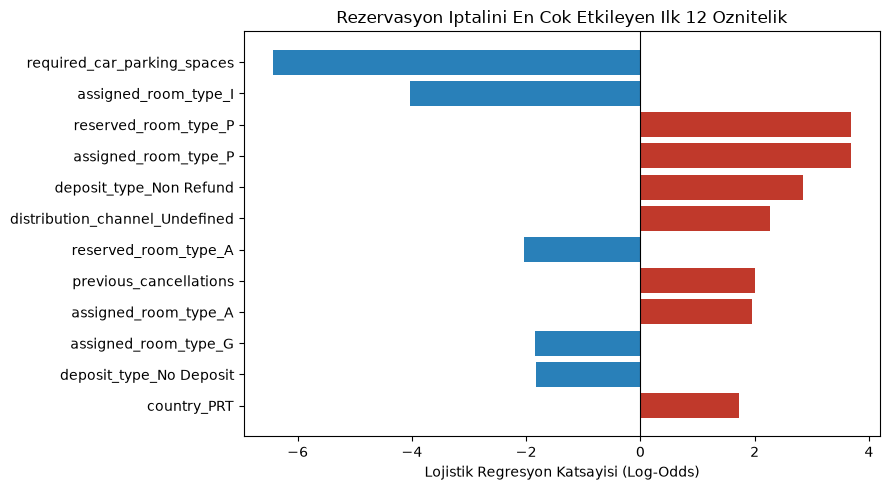

In [10]:
import matplotlib.pyplot as plt

best_lr = grid_lr.best_estimator_
prep = best_lr.named_steps["prep"]

# Donusturulmus sutun isimlerinin manuel olarak birlestirilmesi
cat_feature_names = prep.named_transformers_["cat"].named_steps["encoder"].get_feature_names_out(cat_cols)
country_feature_names = prep.named_transformers_["country"].named_steps["encoder"].get_feature_names_out(["country"])
feature_names = np.concatenate([num_cols, cat_feature_names, country_feature_names])

coefs = best_lr.named_steps["clf"].coef_[0]

coef_df = pd.DataFrame({"Oznitelik": feature_names, "Katsayi": coefs})
coef_df["Mutlak_Deger"] = coef_df["Katsayi"].abs()
top_features = coef_df.sort_values(by="Mutlak_Deger", ascending=False).head(12)

plt.figure(figsize=(9, 5))
colors = ["#c0392b" if x > 0 else "#2980b9" for x in top_features["Katsayi"]]
plt.barh(top_features["Oznitelik"][::-1], top_features["Katsayi"][::-1], color=colors[::-1])
plt.xlabel("Lojistik Regresyon Katsayisi (Log-Odds)")
plt.title("Rezervasyon Iptalini En Cok Etkileyen Ilk 12 Oznitelik")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [11]:
import os
import joblib

os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

# 5-Fold CV sonuclarinin tablo halinde kaydedilmesi
cv_summary = pd.DataFrame([
    {
        "Model": "Baseline (Dummy Classifier)",
        "Accuracy": f"{baseline_scores['test_accuracy'].mean():.4f} ± {baseline_scores['test_accuracy'].std():.4f}",
        "Recall": f"{baseline_scores['test_recall'].mean():.4f} ± {baseline_scores['test_recall'].std():.4f}",
        "F1": f"{baseline_scores['test_f1'].mean():.4f} ± {baseline_scores['test_f1'].std():.4f}",
        "ROC_AUC": f"{baseline_scores['test_roc_auc'].mean():.4f} ± {baseline_scores['test_roc_auc'].std():.4f}",
    },
    {
        "Model": "Lojistik Regresyon",
        "Accuracy": f"{best_lr_scores['test_accuracy'].mean():.4f} ± {best_lr_scores['test_accuracy'].std():.4f}",
        "Recall": f"{best_lr_scores['test_recall'].mean():.4f} ± {best_lr_scores['test_recall'].std():.4f}",
        "F1": f"{best_lr_scores['test_f1'].mean():.4f} ± {best_lr_scores['test_f1'].std():.4f}",
        "ROC_AUC": f"{best_lr_scores['test_roc_auc'].mean():.4f} ± {best_lr_scores['test_roc_auc'].std():.4f}",
    }
])

cv_summary.to_csv("results/cv_part1_abdullah.csv", index=False)
joblib.dump(grid_lr.best_estimator_, "models/best_lr_pipeline.joblib")
print("Part 1 sonuclari ve en iyi model kaydedildi.")
display(cv_summary)

Part 1 sonuclari ve en iyi model kaydedildi.


,Model,Accuracy,Recall,F1,ROC_AUC
0,Baseline (Dummy Classifier),0.6296 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000
1,Lojistik Regresyon,0.8089 ± 0.0021,0.7853 ± 0.0064,0.7528 ± 0.0034,0.8958 ± 0.0024


In [ ]:
import glob
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

# 1. Tum ekip uyelerinin 5-Fold CV sonuclarinin birlestirilmesi
cv_files = sorted(glob.glob("results/cv_part*.csv"))
all_cv_df = pd.concat([pd.read_csv(f) for f in cv_files], ignore_index=True)
print("=== 5-FOLD CAPRAZ DOGRULAMA KARSILASTIRMASI ===")
display(all_cv_df)

# 2. Nihai Test Kumesi (%20) uzerinde tek seferlik degerlendirme
models_to_eval = {
    "Baseline (Dummy)": baseline_pipe.fit(X_train, y_train),
    "Lojistik Regresyon": joblib.load("models/best_lr_pipeline.joblib"),
    "Karar Agaci": joblib.load("models/best_dt_pipeline.joblib"),
    "k-NN": joblib.load("models/best_knn_pipeline.joblib")
}

test_results = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, model in models_to_eval.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    test_results.append({
        "Model": name,
        "Test_Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Test_Recall": round(recall_score(y_test, y_pred), 4),
        "Test_F1": round(f1_score(y_test, y_pred), 4),
        "Test_ROC_AUC": round(roc_auc_score(y_test, y_prob), 4)
    })
    if name != "Baseline (Dummy)":
        RocCurveDisplay.from_predictions(y_test, y_prob, name=name, ax=axes[1])

axes[1].plot([0, 1], [0, 1], "k--", label="Rastgele (0.50)")
axes[1].set_title("Nihai Test Kumesi ROC Egrileri")
axes[1].legend()

# En iyi model icin karmasiklik matrisi (Confusion Matrix)
best_overall = models_to_eval["Lojistik Regresyon"]
ConfusionMatrixDisplay.from_estimator(best_overall, X_test, y_test, cmap="Blues", ax=axes[0])
axes[0].set_title("Lojistik Regresyon - Test Karmasiklik Matrisi")
plt.tight_layout()
plt.show()

print("=== NIHAI TEST KUMESI (%20) SONUCLARI ===")
display(pd.DataFrame(test_results))

# 3. Etik ve Adalet Analizi: Otel turune gore alt grup performansi (City Hotel vs Resort Hotel)
print("=== ALT GRUP ADALET ANALIZI (OTEL TURUNE GORE) ===")
for hotel_type in X_test["hotel"].unique():
    mask = (X_test["hotel"] == hotel_type)
    sub_pred = best_overall.predict(X_test[mask])
    sub_prob = best_overall.predict_proba(X_test[mask])[:, 1]
    print(f"{hotel_type:13s} (n={mask.sum()}) -> Accuracy: {accuracy_score(y_test[mask], sub_pred):.4f} | "
          f"Recall: {recall_score(y_test[mask], sub_pred):.4f} | F1: {f1_score(y_test[mask], sub_pred):.4f} | "
          f"ROC-AUC: {roc_auc_score(y_test[mask], sub_prob):.4f}")